# 29 — Outbreak definition: MA3 vs MA5 vs MA7

Forecast horizon stays3days. Minimum count gate stays5cases over3days. Baselines use28prior matching-window means, with a matching-window exclusion gap to avoid overlapping raw observations. These are different event-label definitions. MA3 remains primary; no model retraining or later-year evaluation. All warning thresholds use calibration only.

Use the final cell to inspect saved results without rerunning.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if (ROOT/"Weikun").is_dir():ROOT=ROOT/"Weikun"
OUTPUT=ROOT/"outbreak_smoothing_outputs"/"smoothing_3_5_7_20261101"
print(OUTPUT.resolve())

C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\outbreak_smoothing_outputs\smoothing_3_5_7_20261101


In [2]:
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score,precision_recall_curve

def event_labels(counts, min_cases=5, sd_multiplier=2, smoothing=3):
    """Causal labels; onset is confirmation, never backdated."""
    s=pd.Series(np.asarray(counts,dtype=float))
    ma=s.rolling(smoothing,min_periods=smoothing).mean()
    hist=ma.shift(smoothing).rolling(28,min_periods=28)
    mean,sd=hist.mean(),hist.std(ddof=1)
    threshold=mean+sd_multiplier*sd
    qualify=(ma>threshold)&(s.rolling(3).sum()>=min_cases)&threshold.notna()
    valid=threshold.notna().to_numpy()
    # Smooth continuous excess with the same sign as the two qualification gates.
    scale=np.maximum(sd.to_numpy(),1.)
    margin=np.minimum((ma.to_numpy()-threshold.to_numpy())/scale,
                      (s.rolling(3).sum().to_numpy()-min_cases+1e-9)/(3*scale))
    active=np.zeros(len(s),bool);onset=np.zeros(len(s),bool)
    in_event=False;off=0
    for k in range(len(s)):
        if in_event:
            off=0 if qualify.iloc[k] else off+1
            if off>=7:in_event=False;off=0
        elif k>0 and qualify.iloc[k] and qualify.iloc[k-1]:
            in_event=True;onset[k]=True
        active[k]=in_event
    return dict(ma=ma.to_numpy(),threshold=threshold.to_numpy(),sd=sd.to_numpy(),
                qualify=qualify.to_numpy(),valid=valid,margin=margin,active=active,onset=onset)

def warning_events(score,eligible,truth_onset,origins,dates,threshold):
    """Seven-day issue cooldown. One alarm matches at most one event."""
    rows=[];events=[]
    for z in range(len(score)):
        event_dates=dates[truth_onset[z]]
        # Denominator: events with at least one scored eligible origin 1..3 days before.
        covered=[d for d in event_dates if np.any(eligible[z]&((d-origins).astype('timedelta64[D]').astype(int)>=1)&((d-origins).astype('timedelta64[D]').astype(int)<=3))]
        matched=set();last=None
        for k,d in enumerate(origins):
            if not eligible[z,k] or not score[z,k]>threshold:continue
            if last is not None and (d-last).astype('timedelta64[D]').astype(int)<7:continue
            last=d
            candidates=[e for e in covered if e not in matched and 1<=int((e-d)/np.timedelta64(1,'D'))<=3]
            target=min(candidates) if candidates else None
            if target is not None:matched.add(target)
            rows.append(dict(region_index=z,forecast_origin=str(d)[:10],matched_event_date=str(target)[:10] if target is not None else '',
                             true_warning=target is not None,lead_days=float((target-d)/np.timedelta64(1,'D')) if target is not None else np.nan))
        for d in covered:events.append(dict(region_index=z,event_date=str(d)[:10],detected=d in matched))
    alarms=pd.DataFrame(rows,columns=['region_index','forecast_origin','matched_event_date','true_warning','lead_days'])
    ev=pd.DataFrame(events,columns=['region_index','event_date','detected'])
    tp=int(alarms.true_warning.sum()) if len(alarms) else 0;fp=len(alarms)-tp
    exposure=int(eligible.sum())
    metrics=dict(events=len(ev),detected_events=int(ev.detected.sum()) if len(ev) else 0,warning_episodes=len(alarms),false_warning_episodes=fp,
                 event_recall=tp/len(ev) if len(ev) else np.nan,warning_precision=tp/len(alarms) if len(alarms) else np.nan,
                 false_warnings_per_30_at_risk_zip_days=fp*30/exposure if exposure else np.nan,
                 mean_lead_days=float(alarms.lead_days.mean()) if len(alarms) else np.nan,
                 median_lead_days=float(alarms.lead_days.median()) if len(alarms) else np.nan,at_risk_zip_days=exposure)
    return metrics,alarms,ev

def run_outbreak(root,output,min_cases=5,sd_multiplier=2,smoothing=3):
    assert smoothing in [3,5,7]
    root,output=Path(root),Path(output);output.mkdir(parents=True,exist_ok=True);fig=output/'figures';fig.mkdir(exist_ok=True)
    paths={'Dynamic Panel FE':root/'rolling_trajectory_outputs/rolling60_weekly_development_20261027/predictions.npz',
           'XGBoost':root/'xgboost_trajectory_outputs/xgb60_weekly_development_20261027/predictions.npz',
           'Random Forest':root/'random_forest_trajectory_outputs/rf60_weekly_development_20261027/predictions.npz'}
    arrays={m:np.load(p,allow_pickle=False) for m,p in paths.items()};ref=next(iter(arrays.values()))
    ids=ref['zip'];origins=ref['forecast_origins'].astype('datetime64[D]')
    for a in arrays.values():
        for k in ['zip','forecast_origins','horizons','actual_cases']:assert np.array_equal(a[k],ref[k]),k
    source=root/'rolling_trajectory_outputs/inputs/nj_daily_features.csv.gz'
    frame=pd.read_csv(source,usecols=['zip','date','cases_today'],dtype={'zip':'string'},parse_dates=['date'])
    frame=frame.loc[frame.zip.isin(ids)&frame.date.between('2020-01-01','2020-12-31')]
    assert not frame.duplicated(['zip','date']).any()
    pivot=frame.pivot(index='zip',columns='date',values='cases_today').reindex(ids)
    dates=pivot.columns.to_numpy().astype('datetime64[D]');counts=pivot.to_numpy()
    assert np.isfinite(counts).all() and (counts>=0).all()
    assert np.all(np.diff(dates)==np.timedelta64(1,'D'))
    pos=np.searchsorted(dates,origins)
    actual=np.stack([counts[:,pos+h] for h in [1,2,3]],axis=-1)
    assert np.array_equal(actual,ref['actual_cases'])
    labs=[event_labels(row,min_cases,sd_multiplier,smoothing) for row in counts]
    onset=np.stack([x['onset'] for x in labs]);active=np.stack([x['active'] for x in labs]);valid=np.stack([x['valid'] for x in labs])
    eligible=(~active[:,pos])&valid[:,pos]
    future=np.stack([onset[:,pos+h] for h in [1,2,3]],axis=-1).any(axis=-1)
    daily=pd.DataFrame({'zip':np.repeat(ids,len(dates)),'date':np.tile(dates,len(ids)),'cases_today':counts.ravel()})
    for name in ['ma','threshold','qualify','active','onset','valid']:daily[name]=np.stack([x[name] for x in labs]).ravel()
    daily.to_csv(output/'daily_event_labels_2020.csv.gz',index=False,compression='gzip')
    eventrows=[]
    for z in range(len(ids)):
        for k in np.flatnonzero(onset[z]):eventrows.append(dict(zip=ids[z],event_date=str(dates[k]),cases_today=counts[z,k],mean3=labs[z]['ma'][k],threshold=labs[z]['threshold'][k]))
    events=pd.DataFrame(eventrows);events.to_csv(output/'event_catalog_2020.csv',index=False)
    byzip=pd.DataFrame({'zip':ids,'events':onset.sum(axis=1),'case_total_2020':counts.sum(axis=1)})
    byzip.to_csv(output/'event_counts_by_zip.csv',index=False)
    events.assign(quarter=pd.to_datetime(events.event_date).dt.to_period('Q').astype(str)).groupby('quarter').size().rename('events').to_csv(output/'event_counts_by_quarter.csv')
    # Verify causality: truncating at a date cannot change any earlier labels.
    for z in [0,len(ids)//2,len(ids)-1]:
        for cutoff in [120,240,330]:
            cut=event_labels(counts[z,:cutoff],min_cases,sd_multiplier,smoothing)
            for key in ['qualify','active','onset']:assert np.array_equal(cut[key],labs[z][key][:cutoff])
    scores={}
    for model,a in arrays.items():
        pred=np.maximum(a['raw_predictions'],0)
        score=np.full(eligible.shape,np.nan)
        # Future thresholds use only pre-origin actuals and the issued predictions.
        for j,k in enumerate(pos):
            history_length=2*smoothing+27
            hist=counts[:,k-history_length+1:k+1]
            seq=np.concatenate([hist,pred[:,j,:]],axis=1)
            means=np.full(seq.shape,np.nan)
            cs=np.cumsum(seq,axis=1)
            means[:,smoothing-1:]=(cs[:,smoothing-1:]-np.concatenate([np.zeros((len(seq),1)),cs[:,:-smoothing]],axis=1))/smoothing
            margins=[]
            for d in range(seq.shape[1]-4,seq.shape[1]):
                baseline=means[:,d-smoothing-27:d-smoothing+1]
                assert baseline.shape[1]==28 and np.isfinite(baseline).all()
                mu=baseline.mean(axis=1);sd=baseline.std(axis=1,ddof=1);scale=np.maximum(sd,1.)
                margins.append(np.minimum((means[:,d]-mu-sd_multiplier*sd)/scale,(seq[:,d-2:d+1].sum(axis=1)-min_cases+1e-9)/(3*scale)))
            margins=np.stack(margins,axis=1)
            score[:,j]=np.maximum.reduce([np.minimum(margins[:,h-1],margins[:,h]) for h in [1,2,3]])
            if j==0:
                for z in [0,100,584]:
                    check=event_labels(seq[z],min_cases,sd_multiplier,smoothing)['margin'][-4:]
                    assert np.allclose(margins[z],check,atol=1e-7), 'vector risk mismatch'
        assert np.isfinite(score).all()
        scores[model]=score
    calibration=(origins>=np.datetime64('2020-04-30'))&(origins<=np.datetime64('2020-08-28'))
    assert (origins[calibration].max()+np.timedelta64(3,'D'))<np.datetime64('2020-09-01')
    assessment=(origins>=np.datetime64('2020-09-01'))&(origins<=np.datetime64('2020-12-28'))
    metrics=[];thresholds=[];curves=[]
    for model,score in scores.items():
        # Fixed rule-based candidates; zero means the forecast satisfies both gates.
        choices=[]
        for q in [0,.25,.5,1,2,3,5,10,np.inf]:
            met,_,_=warning_events(score[:,calibration],eligible[:,calibration],onset,origins[calibration],dates,q)
            choices.append(dict(model=model,threshold=q,**met))
        allowed=[x for x in choices if x['false_warnings_per_30_at_risk_zip_days']<=1]
        chosen=min(allowed,key=lambda x:x['threshold']);thresholds.extend(choices)
        for phase,mask in [('calibration',calibration),('assessment',assessment)]:
            lab=future[:,mask][eligible[:,mask]];sc=score[:,mask][eligible[:,mask]]
            met,alarms,ev=warning_events(score[:,mask],eligible[:,mask],onset,origins[mask],dates,chosen['threshold'])
            ap=average_precision_score(lab,sc) if lab.any() else np.nan
            metrics.append(dict(model=model,phase=phase,threshold=chosen['threshold'],average_precision=ap,
                                positive_origin_share=float(lab.mean()),positive_origins=int(lab.sum()),**met))
            tag=model.lower().replace(' ','_')+'_'+phase
            alarms['zip']=alarms.region_index.map(dict(enumerate(ids)));ev['zip']=ev.region_index.map(dict(enumerate(ids)))
            alarms.to_csv(output/(tag+'_warning_episodes.csv'),index=False);ev.to_csv(output/(tag+'_event_detection.csv'),index=False)
            if phase=='assessment' and lab.any():
                precision,recall,_=precision_recall_curve(lab,sc);curves.append((model,precision,recall,ap,float(lab.mean())))
        pd.DataFrame({'zip':np.repeat(ids,len(origins)),'forecast_origin':np.tile(origins,len(ids)),
                      'eligible':eligible.ravel(),'event_in_next_3_days':future.ravel(),'risk_score':score.ravel()}).to_csv(output/(model.lower().replace(' ','_')+'_risk_scores.csv.gz'),index=False,compression='gzip')
    result=pd.DataFrame(metrics);result.to_csv(output/'warning_metrics.csv',index=False)
    pd.DataFrame(thresholds).to_csv(output/'calibration_threshold_grid.csv',index=False)
    plt.rcParams.update({'font.family':'Arial','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
    f,ax=plt.subplots(1,2,figsize=(11,4));ax[0].hist(byzip.events,bins=np.arange(byzip.events.max()+2)-.5,color='#2563eb');ax[0].set(xlabel='Confirmed events per ZIP in 2020',ylabel='ZIPs')
    q=events.assign(q=pd.to_datetime(events.event_date).dt.to_period('Q').astype(str)).groupby('q').size();ax[1].bar(q.index,q,color='#087f78');ax[1].set(ylabel='Confirmed events',title='Observed rule-defined event counts');f.tight_layout();f.savefig(fig/'01_event_distribution.png',dpi=180);plt.close(f)
    f,ax=plt.subplots(figsize=(7,5))
    for m,p,r,ap,prior in curves:ax.plot(r,p,label=f'{m}: AP={ap:.3f}')
    if curves:ax.axhline(curves[0][-1],ls='--',color='gray',label=f'Positive share={curves[0][-1]:.3f}')
    ax.set(xlabel='Recall',ylabel='Precision',title='Sep-Dec 2020 exploratory assessment');ax.legend();f.tight_layout();f.savefig(fig/'02_precision_recall.png',dpi=180);plt.close(f)
    f,axes=plt.subplots(1,2,figsize=(11,4));a=result[result.phase.eq('assessment')]
    axes[0].bar(a.model,a.event_recall,color=['#64748b','#2563eb','#087f78']);axes[0].set(ylabel='Event recall',ylim=(0,1));axes[1].bar(a.model,a.false_warnings_per_30_at_risk_zip_days,color=['#64748b','#2563eb','#087f78']);axes[1].axhline(1,ls='--',color='gray');axes[1].set(ylabel='False warnings /30 at-risk ZIP-days');f.tight_layout();f.savefig(fig/'03_warning_tradeoff.png',dpi=180);plt.close(f)
    protocol=dict(name='Rule-defined NJ case-surge task v1; not official outbreak labels',baseline=f'Trailing{smoothing}-day mean;28 earlier same-window means from t-{smoothing}-27 through t-{smoothing}; latest{smoothing} positions excluded to avoid shared raw counts',threshold=f'baseline mean +{sd_multiplier} sample SD; minimum3-day sum{min_cases}; strict exceedance',confirmation='2 consecutive qualifying days; onset=second day, never backdate',reset='7 consecutive nonqualifying days; onset cannot recur while active',forecast='Existing raw direct1/2/3-day predictions clipped at0; no refit',risk='max over future confirmation days of min(two consecutive qualification margins); normalized by max(baselineSD,1); count gate incorporated',eligibility='Origin inactive and baseline defined; predicts new confirmation within1..3days',warning='score > calibrated threshold,7-day cooldown after each issued warning',calibration='Origins2020-04-30..2020-08-28; all targets <=Aug31; Aug29-31 origins omitted',assessment='2020-09-01..2020-12-28 exploratory; previously inspected',threshold_selection='smallest fixed nonnegative grid threshold with <=1 false warning per30 at-risk ZIP-days in calibration; no assessment tuning',AP='sklearn average_precision_score, step-integrated PR summary; not trapezoidal area',event_matching='earliest issued alert1..3days before confirmation; one-to-one; denominators only events with eligible scored origins',lead_time='reported only for detected events; misses and false alarms reported alongside',limitations=['Research proxy labels, not independently adjudicated outbreaks','Onset records missing excluded; retrospective availability assumption','Static2021 covariates and unvalidated ZIP-ZCTA linkage','2020 thresholds/definitions are exploratory; later assessment is not an untouched test'],sources={m:dict(path=str(p),sha256=hashlib.sha256(p.read_bytes()).hexdigest()) for m,p in paths.items()})
    protocol['smoothing_days']=smoothing;protocol['count_gate_window_days']=3;protocol['forecast_horizon_days']=3;protocol['min_cases']=min_cases;protocol['sd_multiplier']=sd_multiplier
    (output/'task_definition.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8')
    summary=dict(regions=len(ids),origins=len(origins),events_2020=len(events),zips_with_events=int((byzip.events>0).sum()),qualifying_zip_days=int(sum(x['qualify'].sum() for x in labs)),matched_targets_verified=True,causal_prefix_checks_passed=True,no_model_refit=True,calibration_targets_end=str(origins[calibration].max()+np.timedelta64(3,'D')),assessment_origins_start=str(origins[assessment].min()))
    (output/'verification.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
    report='# 病例激增任务v1：探索性结果\n\n'+json.dumps(summary,ensure_ascii=False,indent=2)+'\n\n'+result.to_string(index=False)+'\n\n先看事件数量与分布，再看assessment行。AP的参考是positive_origin_share，不是0.5。Lead time只描述检出的事件，不能忽略漏报。报警阈值只在4—8月选择；9—12月不调阈值。事件起点为第二次满足条件的确认日，不是生物学真实爆发日。误报预算按非活动、可评分的ZIP-days归一化。\n\n如果最小阈值0已满足宽松的1/30误报预算，就保留0，不根据assessment寻找更好的阈值。无事件的地区也必须保留。后续先审查事件例子与敏感性，再决定冻结方案；不把研究定义当成官方疫情判定。'
    report+='\n\n注意：确认日需要连续两天，因此提前1天的成功预警可能已有首个异常日作为输入。它不是在任何异常出现前的预警；也不能解释为已验证感染爆发。事件基线采用28天移动均值，持续缓慢上升可能被适应性基线吸收，数值依赖该代理定义。校准origin截至8/28，使三天目标不跨9/1。\n'
    (output/'RESULTS_CN.md').write_text(report,encoding='utf-8')
    print(json.dumps(summary));print(result.to_string(index=False));return result



import contextlib,io
def run_smoothing(root,output,primary=None):
    root,output=Path(root),Path(output);output.mkdir(parents=True,exist_ok=True)
    primary=Path(primary) if primary else root/'outbreak_task_outputs/case_surge_v1_20261101'
    fig=output/'figures';fig.mkdir(exist_ok=True)
    metrics=[];events=[];leads=[];daily={}
    source_hash=hashlib.sha256((primary/'warning_metrics.csv').read_bytes()).hexdigest()
    for window in [3,5,7]:
        print('Comparing smoothing window:',window,flush=True)
        folder=output/f'MA{window}'
        with contextlib.redirect_stdout(io.StringIO()):r=run_outbreak(root,folder,smoothing=window)
        r['smoothing_days']=window;metrics.append(r)
        daily[window]=pd.read_csv(folder/'daily_event_labels_2020.csv.gz',dtype={'zip':'string'},parse_dates=['date'])
        ec=pd.read_csv(folder/'event_catalog_2020.csv',dtype={'zip':'string'},parse_dates=['event_date'])
        events.append(dict(smoothing_days=window,events_2020=len(ec),zips_with_events=ec.zip.nunique()))
        if window==3:
            old=pd.read_csv(primary/'warning_metrics.csv').sort_values(['model','phase']).reset_index(drop=True)
            new=r.sort_values(['model','phase']).reset_index(drop=True)
            for col in ['average_precision','event_recall','warning_precision','mean_lead_days','events','false_warning_episodes']:
                assert np.allclose(old[col],new[col],equal_nan=True),col
        for model in r.model.unique():
            tag=model.lower().replace(' ','_')
            a=pd.read_csv(folder/(tag+'_assessment_warning_episodes.csv'),dtype={'zip':'string'},parse_dates=['forecast_origin'])
            e=pd.read_csv(folder/(tag+'_assessment_event_detection.csv'))
            truth=daily[window].set_index(['zip','date'])
            detected=a.loc[a.true_warning].copy()
            assert len(detected)==int(e.detected.sum())
            for h in [1,2,3]:
                q=detected.loc[detected.lead_days.eq(h)]
                leads.append(dict(smoothing_days=window,model=model,lead_days=h,detected_events=len(q),eligible_events=len(e),recall_of_all_events=len(q)/len(e)))
            n=int(sum(bool(truth.loc[(z,d),'qualify']) for z,d in zip(detected.zip,detected.forecast_origin)))
            leads.append(dict(smoothing_days=window,model=model,lead_days='SUMMARY',detected_events=len(detected),eligible_events=len(e),recall_of_all_events=len(detected)/len(e),share_already_qualifying=n/len(detected),recall_at_least_2_days=int((detected.lead_days>=2).sum())/len(e)))
    full=pd.concat(metrics,ignore_index=True);full.to_csv(output/'smoothing_metrics_all_phases.csv',index=False)
    assessment=full.loc[full.phase.eq('assessment')].copy();assessment.to_csv(output/'assessment_comparison.csv',index=False)
    pd.DataFrame(events).to_csv(output/'event_count_comparison.csv',index=False)
    lead=pd.DataFrame(leads);lead.to_csv(output/'lead_time_comparison.csv',index=False)
    models=['Dynamic Panel FE','XGBoost','Random Forest'];colors=['#64748b','#2563eb','#087f78']
    f,axes=plt.subplots(2,2,figsize=(12,8))
    for ax,col,title in zip(axes.ravel(),['average_precision','event_recall','warning_precision','positive_origin_share'],['Average precision','Event recall','Warning precision','Positive origin share (different labels)']):
        for m,c in zip(models,colors):
            q=assessment[assessment.model.eq(m)].sort_values('smoothing_days');ax.plot(q.smoothing_days,q[col],'o-',color=c,label=m)
        ax.set(xticks=[3,5,7],xlabel='Trailing mean window (days)',title=title);ax.grid(alpha=.2)
    axes[0,0].legend(fontsize=9);f.suptitle('3 /5 /7-day smoothing; three-day forecast horizon unchanged');f.tight_layout();f.savefig(fig/'01_smoothing_metrics.png',dpi=180);plt.close(f)
    f,axes=plt.subplots(1,2,figsize=(11,4));ev=pd.DataFrame(events)
    axes[0].bar(ev.smoothing_days.astype(str),ev.events_2020,color=colors);axes[0].set(xlabel='Smoothing days',ylabel='2020 rule-defined events')
    ss=lead[lead.lead_days.eq('SUMMARY')]
    for m,c in zip(models,colors):
        q=ss[ss.model.eq(m)];axes[1].plot(q.smoothing_days,q.recall_at_least_2_days,'o-',label=m,color=c)
    axes[1].set(xticks=[3,5,7],xlabel='Smoothing days',ylabel='Recall with at least2-day lead');axes[1].legend(fontsize=9);f.tight_layout();f.savefig(fig/'02_events_and_early_recall.png',dpi=180);plt.close(f)
    # Same ZIP/date window for all rules, preselected from Notebook28's true-warning illustration.
    f,axes=plt.subplots(3,1,figsize=(11,8),sharex=True)
    for ax,w in zip(axes,[3,5,7]):
        d=daily[w];d=d.loc[d.zip.eq('07930')&d.date.between('2020-11-05','2020-12-05')]
        ax.plot(d.date,d.cases_today,color='#CBD5E1',label='Recorded daily cases');ax.plot(d.date,d.ma,color='#2563eb',label=f'Actual MA{w}')
        ax.plot(d.date,d.threshold,'--',color='#D94841',label=f'MA{w} baseline mean +2SD')
        q=d[d.onset];ax.scatter(q.date,q.ma,color='#7C3AED',marker='*',s=100,label='Event confirmation')
        ax.set(title=f'ZIP07930, {w}-day smoothing',ylabel='Cases / mean cases');ax.legend(ncol=2,fontsize=8)
    f.autofmt_xdate();f.tight_layout();f.savefig(fig/'03_same_zip_event_definitions.png',dpi=180);plt.close(f)
    assert hashlib.sha256((primary/'warning_metrics.csv').read_bytes()).hexdigest()==source_hash
    definition=dict(smoothing_windows=[3,5,7],primary=3,forecast_horizon=3,history_baseline='28 same-window mean observations ending t-window; excludes latest window positions so raw baseline does not overlap current window',count_gate='UNCHANGED: last3days total >=5, even for MA5/7',confirmation='2consecutive qualifying days; second day is onset',reset_and_cooldown='unchanged7days',warning_threshold='each definition calibrates on Apr30-Aug28 origins only; targets<=Aug31; fixed grid and <=1false/30at-riskZIP-days policy',assessment='Sep1-Dec28 2020 exploratory',interpretation='Definitions change labels, prevalence, active-day exclusions and event denominators. Compare model ranking within each rule; higher AP across windows does not establish a better forecasting model.',checks='MA3 replicates Notebook27, prefix-causality and vector/scalar score checks in all3runs, source27unchanged',no_model_refit=True,no_2021_2023_outcomes=True)
    (output/'comparison_definition.json').write_text(json.dumps(definition,indent=2),encoding='utf-8')
    report='# Notebook29：3、5、7天均值对照\n\n仅改变病例平滑窗口，并让基线使用相同窗口。为避免当前和基线共享原始病例，基线排除最近相同窗口长度的均值位置。这是配套定义的变化，不是仅替换当前均值而继续使用MA3基线。\n\n仍用此前28个均值、+2SD、最近3天累计至少5例、连续2天确认、7天结束/冷却。预测范围始终未来3天，未重新训练，未使用2021—2023年。主方案仍为MA3。\n\n## 事件数\n\n'+ev.to_string(index=False)+'\n\n## 9—12月\n\n'+assessment[['smoothing_days','model','average_precision','positive_origin_share','events','event_recall','warning_precision','mean_lead_days','threshold']].to_string(index=False)+'\n\n## 至少提前2天与已出现异常条件\n\n'+ss.to_string(index=False)+'\n\n先看01_smoothing_metrics.png，再看03同一ZIP事件定义图。不同窗口定义不同事件，不能只以最高AP挑定义。更长窗口有更多已观测历史成分、更平滑；分数改善不等于能更早捕捉真实疫情。MA5/7在未来日期的计算依然只用截至origin的真实值及本次3个预测值，不使用未来真实病例。\n'
    (output/'RESULTS_CN.md').write_text(report,encoding='utf-8')
    print(ev.to_string(index=False));print(assessment[['smoothing_days','model','average_precision','event_recall','warning_precision','mean_lead_days']].to_string(index=False));return assessment


In [3]:
comparison=run_smoothing(ROOT,OUTPUT)
display(comparison)

Comparing smoothing window: 3
Comparing smoothing window: 5
Comparing smoothing window: 7
 smoothing_days  events_2020  zips_with_events
              3         1838               496
              5         1755               492
              7         1625               491
 smoothing_days            model  average_precision  event_recall  warning_precision  mean_lead_days
              3 Dynamic Panel FE           0.520026      0.786030           0.679144        1.304837
              3          XGBoost           0.542057      0.729443           0.836714        1.135758
              3    Random Forest           0.540082      0.793103           0.766667        1.230769
              5 Dynamic Panel FE           0.612649      0.824399           0.684049        1.511211
              5          XGBoost           0.635929      0.797597           0.842773        1.289687
              5    Random Forest           0.635364      0.826248           0.765411        1.434004
              7

,model,phase,threshold,average_precision,positive_origin_share,positive_origins,events,detected_events,warning_episodes,false_warning_episodes,event_recall,warning_precision,false_warnings_per_30_at_risk_zip_days,mean_lead_days,median_lead_days,at_risk_zip_days,smoothing_days
1,Dynamic Panel FE,assessment,0,0.520026,0.059398,3299,1131,889,1309,420,0.786030,0.679144,0.226859,1.304837,1.0,55541,3
3,XGBoost,assessment,0,0.542057,0.059398,3299,1131,825,986,161,0.729443,0.836714,0.086963,1.135758,1.0,55541,3
5,Random Forest,assessment,0,0.540082,0.059398,3299,1131,897,1170,273,0.793103,0.766667,0.147459,1.230769,1.0,55541,3
7,Dynamic Panel FE,assessment,0,0.612649,0.057126,3125,1082,892,1304,412,0.824399,0.684049,0.225943,1.511211,1.0,54704,5
9,XGBoost,assessment,0,0.635929,0.057126,3125,1082,863,1024,161,0.797597,0.842773,0.088293,1.289687,1.0,54704,5
11,Random Forest,assessment,0,0.635364,0.057126,3125,1082,894,1168,274,0.826248,0.765411,0.150263,1.434004,1.0,54704,5
13,Dynamic Panel FE,assessment,0,0.633050,0.053904,2878,992,784,1179,395,0.790323,0.664970,0.221948,1.572704,1.0,53391,7
15,XGBoost,assessment,0,0.650027,0.053904,2878,992,779,932,153,0.785282,0.835837,0.085970,1.331194,1.0,53391,7
17,Random Forest,assessment,0,0.652963,0.053904,2878,992,774,1044,270,0.780242,0.741379,0.151711,1.457364,1.0,53391,7


,smoothing_days,events_2020,zips_with_events
0,3,1838,496
1,5,1755,492
2,7,1625,491


,model,phase,threshold,average_precision,positive_origin_share,positive_origins,events,detected_events,warning_episodes,false_warning_episodes,event_recall,warning_precision,false_warnings_per_30_at_risk_zip_days,mean_lead_days,median_lead_days,at_risk_zip_days,smoothing_days
0,Dynamic Panel FE,assessment,0,0.520026,0.059398,3299,1131,889,1309,420,0.786030,0.679144,0.226859,1.304837,1.0,55541,3
1,XGBoost,assessment,0,0.542057,0.059398,3299,1131,825,986,161,0.729443,0.836714,0.086963,1.135758,1.0,55541,3
2,Random Forest,assessment,0,0.540082,0.059398,3299,1131,897,1170,273,0.793103,0.766667,0.147459,1.230769,1.0,55541,3
3,Dynamic Panel FE,assessment,0,0.612649,0.057126,3125,1082,892,1304,412,0.824399,0.684049,0.225943,1.511211,1.0,54704,5
4,XGBoost,assessment,0,0.635929,0.057126,3125,1082,863,1024,161,0.797597,0.842773,0.088293,1.289687,1.0,54704,5
5,Random Forest,assessment,0,0.635364,0.057126,3125,1082,894,1168,274,0.826248,0.765411,0.150263,1.434004,1.0,54704,5
6,Dynamic Panel FE,assessment,0,0.633050,0.053904,2878,992,784,1179,395,0.790323,0.664970,0.221948,1.572704,1.0,53391,7
7,XGBoost,assessment,0,0.650027,0.053904,2878,992,779,932,153,0.785282,0.835837,0.085970,1.331194,1.0,53391,7
8,Random Forest,assessment,0,0.652963,0.053904,2878,992,774,1044,270,0.780242,0.741379,0.151711,1.457364,1.0,53391,7


,smoothing_days,model,lead_days,detected_events,eligible_events,recall_of_all_events,share_already_qualifying,recall_at_least_2_days
0,3,Dynamic Panel FE,1,661,1131,0.584439,NaN,NaN
1,3,Dynamic Panel FE,2,185,1131,0.163572,NaN,NaN
2,3,Dynamic Panel FE,3,43,1131,0.038019,NaN,NaN
3,3,Dynamic Panel FE,SUMMARY,889,1131,0.786030,0.754781,0.201592
4,3,XGBoost,1,725,1131,0.641026,NaN,NaN
5,3,XGBoost,2,88,1131,0.077807,NaN,NaN
6,3,XGBoost,3,12,1131,0.010610,NaN,NaN
7,3,XGBoost,SUMMARY,825,1131,0.729443,0.888485,0.088417
8,3,Random Forest,1,717,1131,0.633952,NaN,NaN
9,3,Random Forest,2,153,1131,0.135279,NaN,NaN


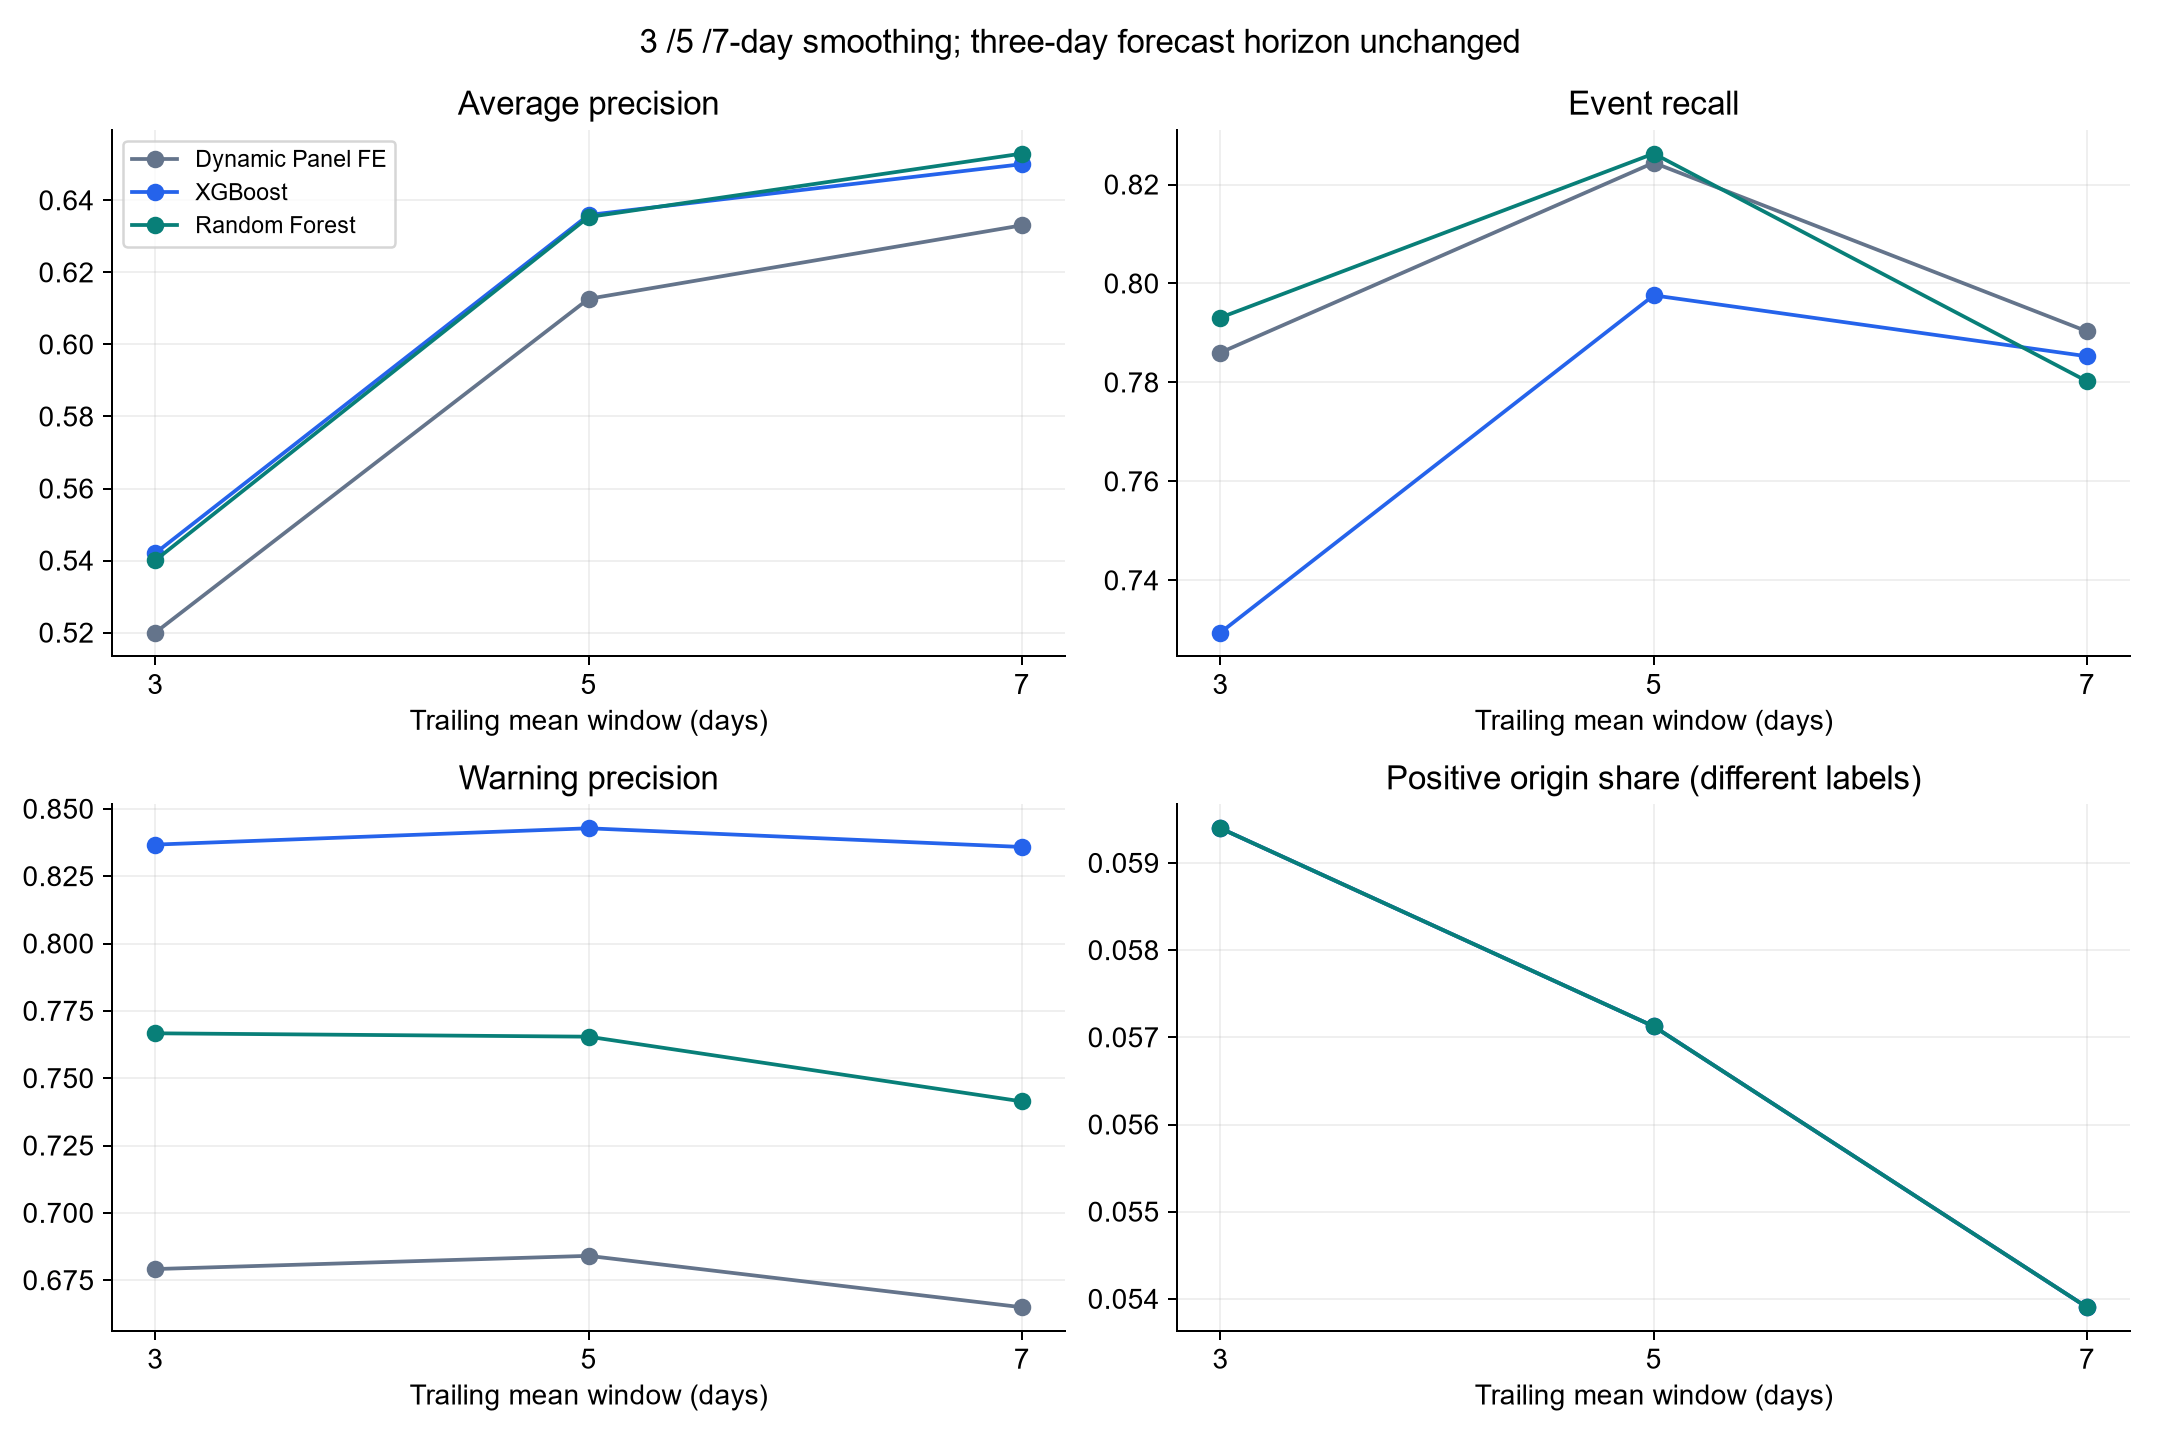

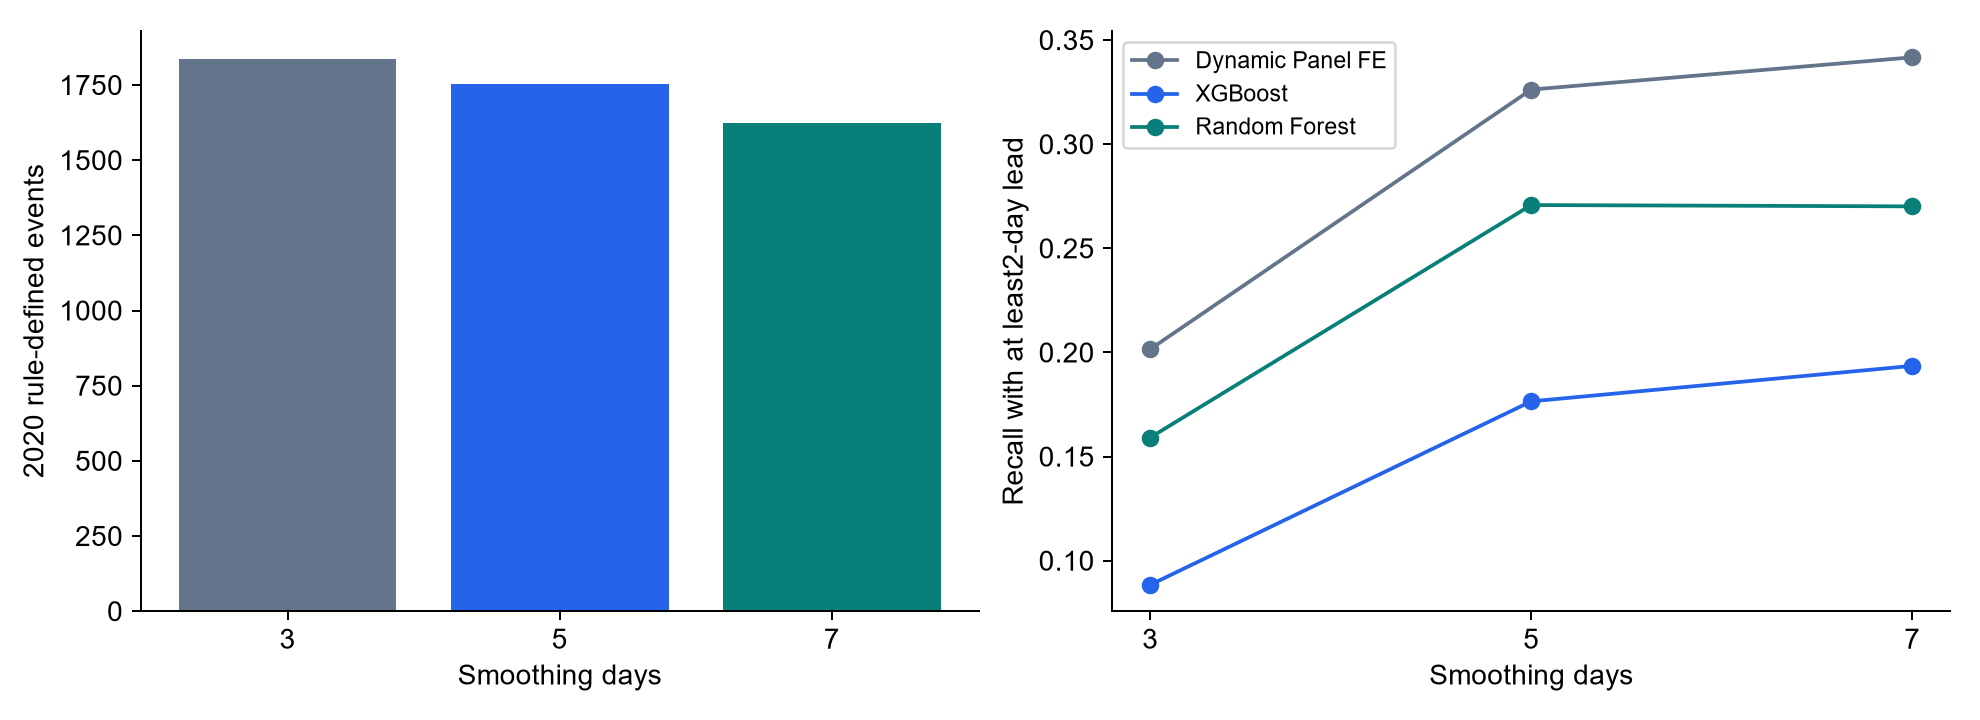

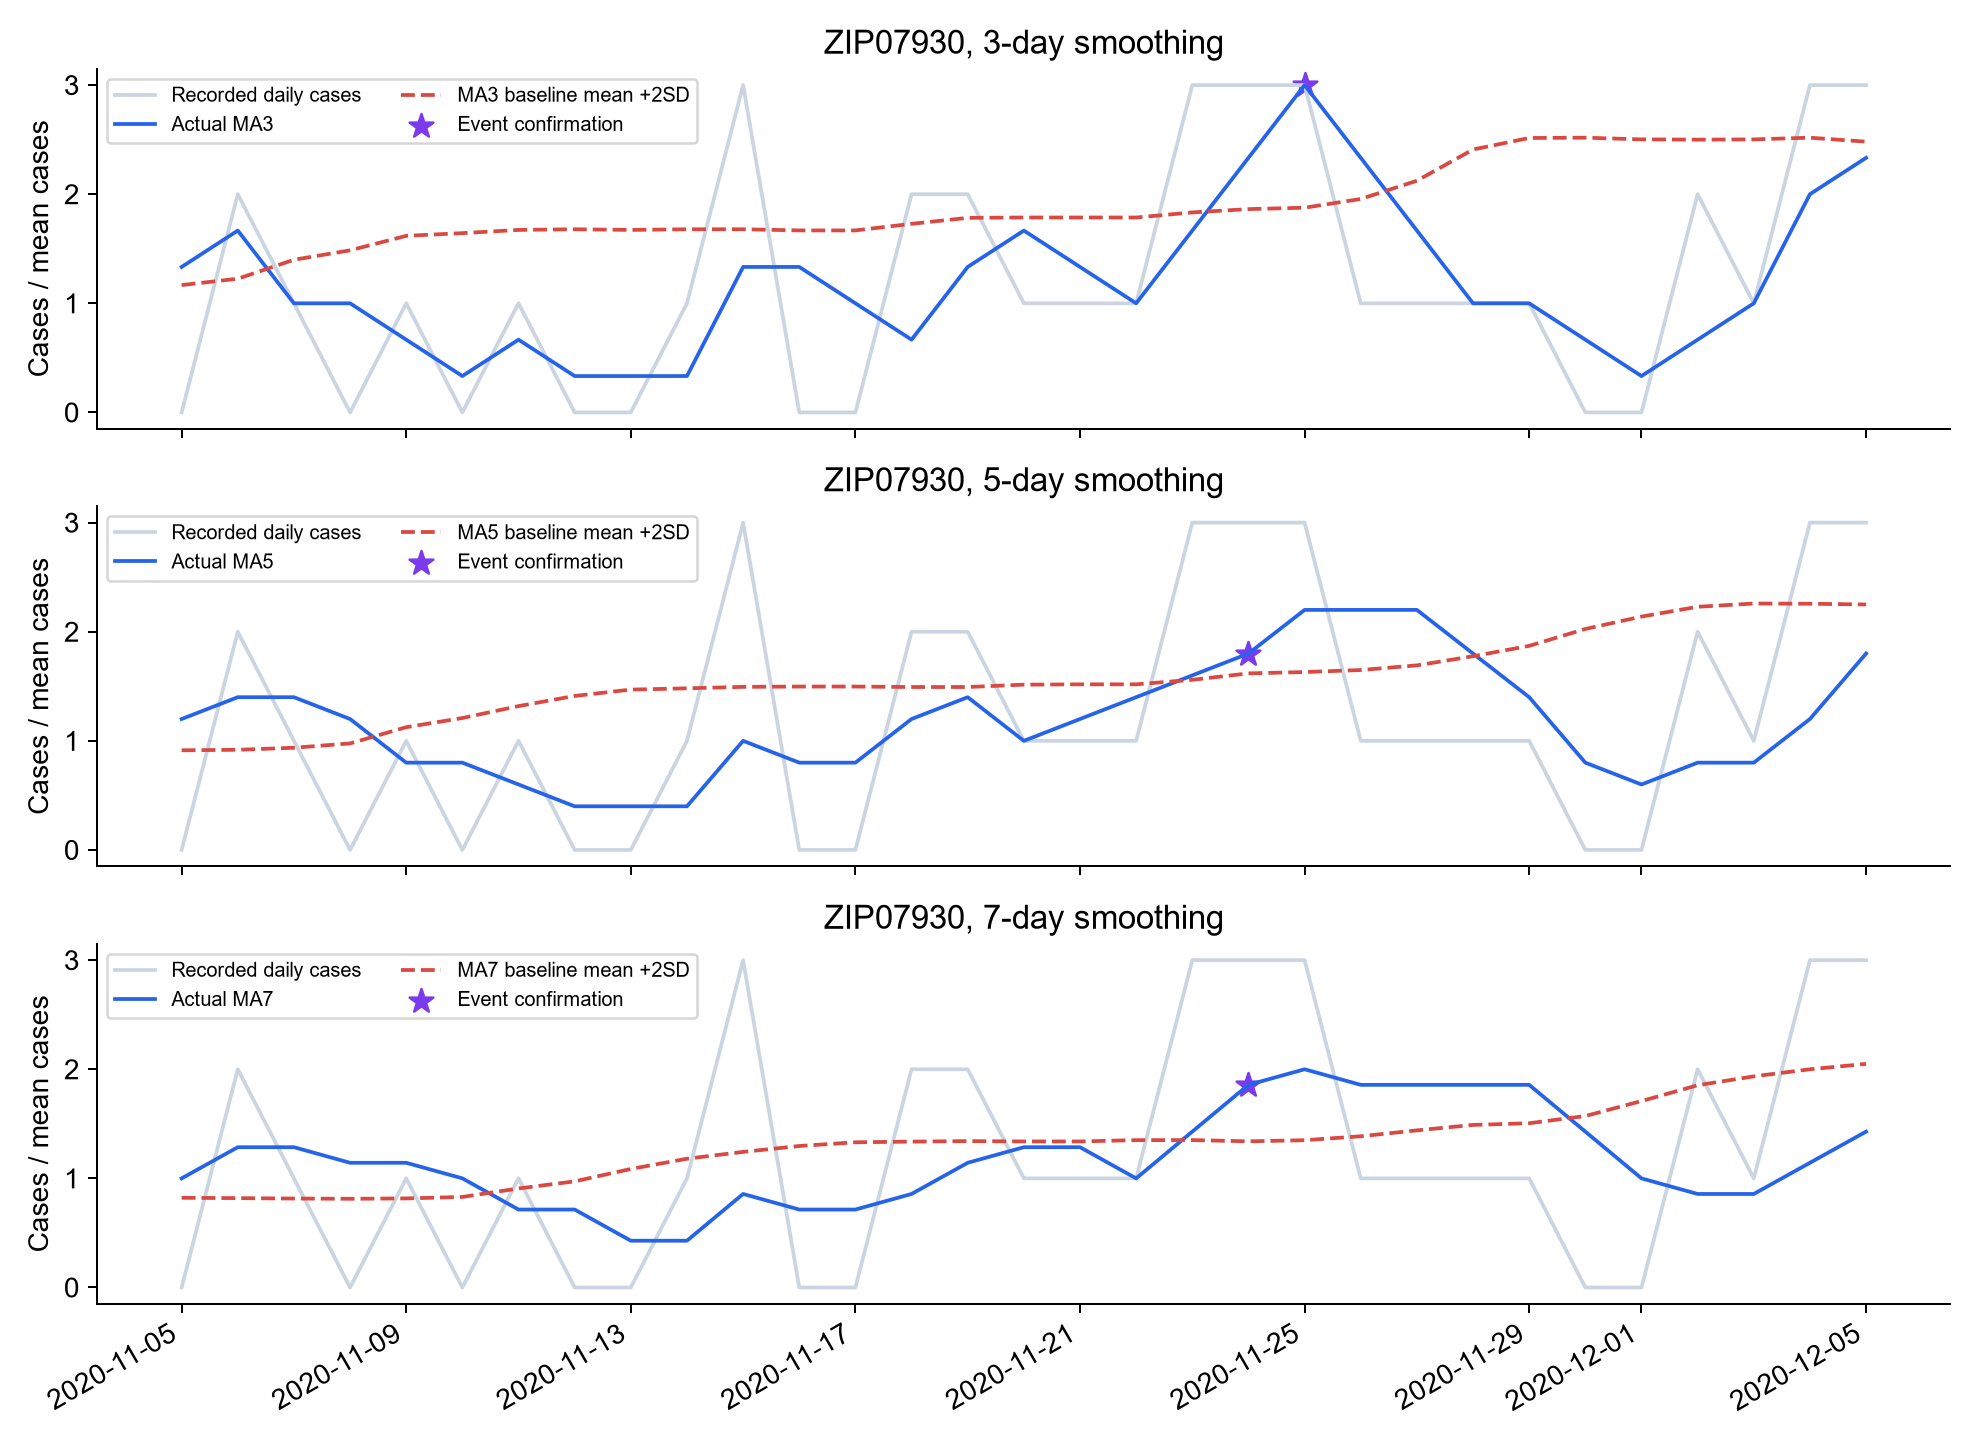

In [4]:
import pandas as pd
from IPython.display import display,Image
display(pd.read_csv(OUTPUT/"event_count_comparison.csv"))
display(pd.read_csv(OUTPUT/"assessment_comparison.csv"))
display(pd.read_csv(OUTPUT/"lead_time_comparison.csv"))
for name in ["01_smoothing_metrics.png","02_events_and_early_recall.png","03_same_zip_event_definitions.png"]:
    display(Image(filename=str(OUTPUT/"figures"/name)))